# Zomato Banglore Restaurants - EDA
** Business Problem: Best Location, Type and Price

# Libraries and Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\gvaib\Downloads\zomato.csv\zomato.csv")
df

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield


## Data understanding
In this step Before recommending where and how to open a new restaurant in banglore , 
I first assessed whether the data can be trusted to answer that question.
The dataset covers restaurants listed on Zomato, with details such as location,restaurant type,cuisine,cost
for two, rating,votes, online ordering and table booking. These fields map directly to the key business decisions:
where to open(location), what do offer (type and cuisine), how to price(cost for two) and which services to provide
(online order,table booking). I checked the dataset's size, column data types, missing values and duplicate rows to 
understand its reliability.Rating and cost are the most important matrics for judging a restaurant's performance and
pricing,so any gaps or formatting issues in them could mislead the analysis.Missing ratings, for example, mostly
belong to new or unrated restaurants,which should not be treated as poor performers.These findings decide how the data
is cleaned in the next step so that final insights are dependable.

In [6]:
# Checking the number of rows (restaurants) and columns (attributes) to understand the scale of data.
print(df.shape)

(51717, 17)


In [8]:
# Reviewing each column's type and not null count to find columns, like 'rate' and 'cost',stored in the wrong format.
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [9]:
# Counting empty values per column to decide how to handle incomplete data,such as unrated resturants.
df.isnull().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [11]:
# Checking for repeated rows that could inflate restaurant counts and distort insights.
print(df.duplicated().sum())

0


# Observation: The dataset has (51717) rows and (17) columns,and (0) duplicate rows were found, so cleaning is required before analysis.

## Data Cleaning
Before analysis,I cleaned the data so that ratings, costs and locations can be compare reliably. Each step below fixes
an issue found in the data understanding section.

In [25]:
## Renaming columns: Simplifying long column names (for example,'approx_cost(for two people)' to 'cost') to make the code easier to read and write
df=df.rename(columns={"approx_cost(for two people)":"cost",
                      "listed_in(type)":"type",
                      "listed_in(city)":"city"})
df

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,cost,reviews_list,menu_item,type,city
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield


In [26]:
## Removing duplicates: Dropping repeated rows so that each restaurant is counted only once.
df=df.drop_duplicates()
df

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,cost,reviews_list,menu_item,type,city
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield


In [47]:
## Cleaning ratings: Converting 'rate' from text (like "4.1/5") to a number. values such as "NEW" and "-" are set to missing,because they mean 
#                     the restaurant is not yet rated,not that it performs poorly.
df["rate"]=df["rate"].replace(["new","-"],np.nan)
df["rate"]=df["rate"].astype(str).str.replace("/5","").str.strip()
df["rate"]=pd.to_numeric(df["rate"],errors="coerce").astype("float64")
df["rate"]

0        4.1
1        4.1
2        3.8
3        3.7
4        3.8
        ... 
51712    3.6
51713    NaN
51714    NaN
51715    4.3
51716    3.4
Name: rate, Length: 51717, dtype: float64

In [48]:
## Cleaning cost: Removing commas from values like "1,200" and converting 'cost' to a number so that price comparisons and averages can be calculated. 
df["cost"]=df["cost"].astype(str).str.replace(",","")
df["cost"]=pd.to_numeric(df["cost"],errors="coerce")
df["cost"]

0         800.0
1         800.0
2         800.0
3         300.0
4         600.0
          ...  
51712    1500.0
51713     600.0
51714    2000.0
51715    2500.0
51716    1500.0
Name: cost, Length: 51717, dtype: float64

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   url           51717 non-null  str    
 1   address       51717 non-null  str    
 2   name          51717 non-null  str    
 3   online_order  51717 non-null  str    
 4   book_table    51717 non-null  str    
 5   rate          41665 non-null  str    
 6   votes         51717 non-null  int64  
 7   phone         50509 non-null  str    
 8   location      51696 non-null  str    
 9   rest_type     51490 non-null  str    
 10  dish_liked    23639 non-null  str    
 11  cuisines      51672 non-null  str    
 12  cost          51371 non-null  float64
 13  reviews_list  51717 non-null  str    
 14  menu_item     51717 non-null  str    
 15  type          51717 non-null  str    
 16  city          51717 non-null  str    
dtypes: float64(1), int64(1), str(15)
memory usage: 6.7 MB


In [34]:
print("Duplicates:",df.duplicated().sum())

Duplicates: 0


In [35]:
print(df[["rate","cost"]].isnull().sum())

rate    10052
cost      346
dtype: int64


In [ ]:
## Observation: After cleaning,'rate' and 'cost' are numeric.[0]duplicate rows were removed, and [10052] ratings and[346] cost values remain missing.
#                Missing values are excluded only from the calculations that need them,so the rest of the data stayes in use.
                

## Exploratory Data Analysis
# Q. Which locations have the most restaurants?
** why it matters: Locations with many restaurants show high demand but also high competition,which is key when choosing where
   to open a new restaurants.

In [36]:
# Unique restaurants per location(same resataurant can appear is multiple rows)
top_locations=(df.groupby("location")["name"].nunique().sort_values(ascending=False).head(10))
top_locations

location
Whitefield           824
BTM                  699
Electronic City      696
HSR                  684
Marathahalli         659
Indiranagar          526
JP Nagar             502
Bannerghatta Road    448
Jayanagar            352
Bellandur            349
Name: name, dtype: int64

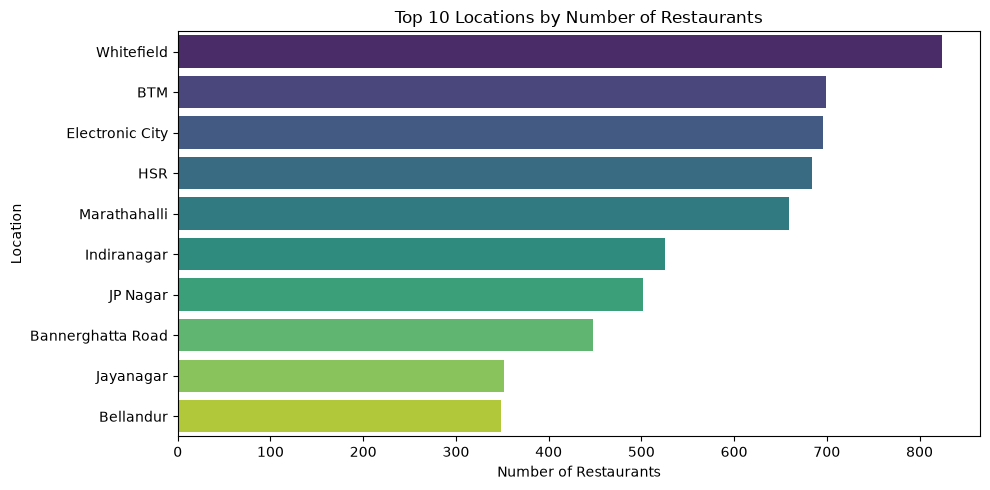

In [42]:
plt.figure(figsize=(10,5))
sns.barplot(x=top_locations.values, y=top_locations.index,hue=top_locations.index, palette="viridis",legend=False)
plt.title("Top 10 Locations by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

### Q.Do restaurants with online ordering get better ratings?
Why: It shows whether offering online orders is linked to higher customer satisfaction, which helps decide if a new restaurant
should offer it from day one. 

In [53]:
# Same restaurent appears in multiple rows (different listing types), so keep one row per restaurant
df_rest=df.drop_duplicates(subset=["name","location"]).copy()
print(df_rest.shape)

(12151, 17)


In [54]:
# Average, median rating and count for each group
print(df_rest.groupby("online_order")["rate"].agg(["mean","median","count"]).round(2))

              mean  median  count
online_order                     
No            3.59     3.6   3513
Yes           3.65     3.7   5524


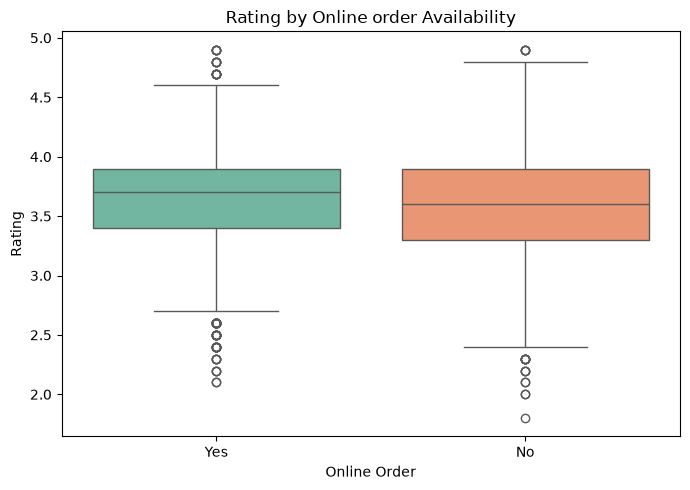

In [55]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df_rest, x="online_order", y="rate", palette="Set2",hue="online_order", legend=False)
plt.title("Rating by Online order Availability")
plt.xlabel("Online Order")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

## Chart Note: Both groups have similar rating ranges,with the "Yes" group sitting slightly higher. this matche the averages above.

# Q.Do restaurants offering table booking get better rating?
**Why: Table booking is usually offered by sit-down, higher-end restaurants.This shows whether the service is linked to better ratings and higher              prices.  

In [57]:
print(df_rest.groupby("book_table")[["rate","cost"]].agg(["mean","median","count"]))

                rate                      cost               
                mean median count         mean  median  count
book_table                                                   
No          3.574255    3.6  8122   420.355843   400.0  11151
Yes         4.115191    4.1   915  1301.277955  1200.0    939


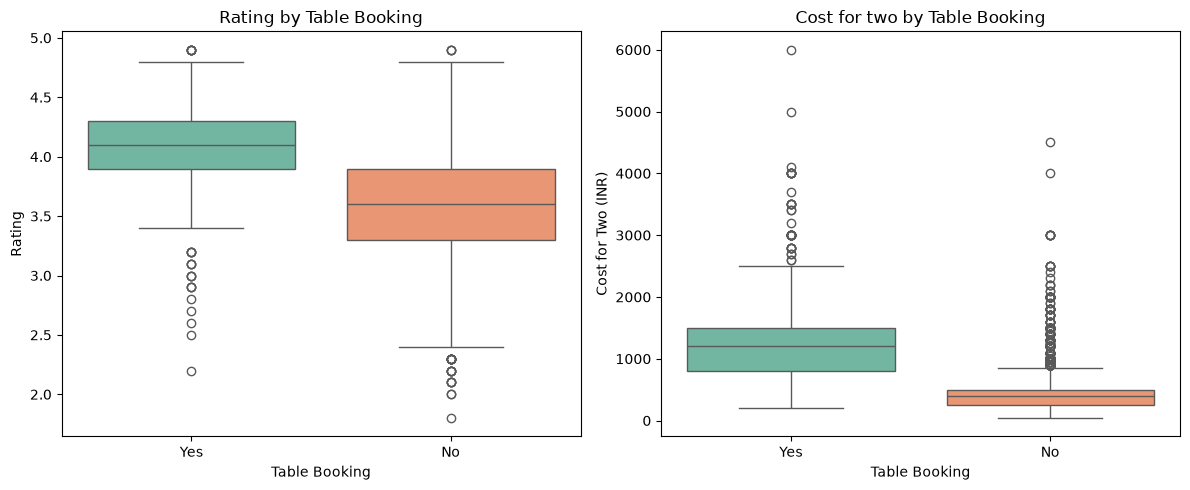

In [58]:
fig, axes=plt.subplots(1,2, figsize=(12,5))
sns.boxplot(data=df_rest, x="book_table", y="rate", hue="book_table", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Rating by Table Booking")
axes[0].set_xlabel("Table Booking")
axes[0].set_ylabel("Rating")

sns.boxplot(data=df_rest, x="book_table", y="cost", hue="book_table", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Cost for two by Table Booking")
axes[1].set_xlabel("Table Booking")
axes[1].set_ylabel("Cost for Two (INR)")

plt.tight_layout()
plt.show()

**Insight:Restaurants offering table booking have an average rating of [4.12] and an average cost for two of [1301], compared with [3.57] and [420]
           for those without.This suggests table booking is mostly offered by higher-priced / better-rated restaurants. This shows coorelation,
           not causation.

## Q.Which restaurant types are the most common and the best rated?
**Why:Shows which formats (Casual Dining, Cafe, Quick Bites,etc.) dominate the market and which ones earn better ratings. 

In [72]:
type_summary=(df_rest.groupby("rest_type").agg(restaurants=("name","count"),
                                               avg_rating=("rate","mean"),
                                               avg_cost=("cost","mean")).sort_values("restaurants",ascending=False).head(10).round(2))
print(type_summary)

                    restaurants  avg_rating  avg_cost
rest_type                                            
Quick Bites                4876        3.52    309.28
Casual Dining              2188        3.68    754.34
Delivery                    924        3.55    435.89
Takeaway, Delivery          732        3.51    380.16
Dessert Parlor              539        3.81    320.19
Cafe                        534        3.76    600.38
Bakery                      311        3.60    374.18
Beverage Shop               241        3.62    226.06
Food Court                  172        3.40    438.12
Casual Dining, Bar          152        3.95   1151.97


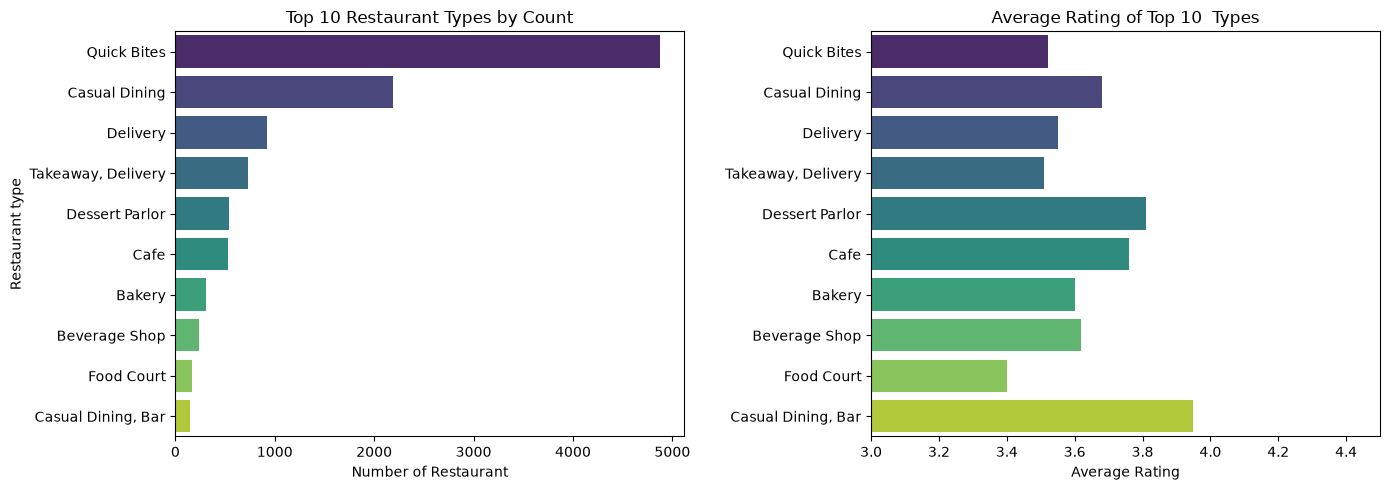

In [76]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.barplot(x=type_summary["restaurants"], y=type_summary.index, hue=type_summary.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Restaurant Types by Count")
axes[0].set_xlabel("Number of Restaurant")
axes[0].set_ylabel("Restaurant type")

sns.barplot(x=type_summary["avg_rating"], y=type_summary.index, hue=type_summary.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Average Rating of Top 10  Types")
axes[1].set_xlabel("Average Rating")
axes[1].set_ylabel(" ")
axes[1].set_xlim(3,4.5)
plt.tight_layout()
plt.show()

**Insight:Quick Bites is by far the most common restaurant type (about 4900 restaurants), followed by casual dining (about 2100), while all other types
          have well under 1000 each. However,Quick Bites has one of the lower average ratings (about 3.5), whereas Casual Dining(about 3.75),cafe
          (3.75), Dessert Parlor(about 3.85) abd Casual Dining Bar(about 3.95) rate higher. Food court has the lowest rating (about 3.3). the
           best rated types ae also among the smaller segments,which suggests less competition and stronger customer satisfaction in these formats.
           Note that the rating axis starts at 3.0, so the gaps look larger in the chart than they are. this shows correlation,not causation.     

**Takeway:Quick Bites is by far the most croweded segment with average ratings, while sit-down and dessert formats combine good rating with fewer 
          competitiors, making them more attractive entry options.

### Q.What are the most popular cuisines?
**Why: Shows which cuisines have the most rstaurants and the best ratings,which help decide what to serve.

In [79]:
cuisine_df=df_rest.dropna(subset=["cuisines"]).copy()
cuisine_df["cuisine"]=cuisine_df["cuisines"].str.split(",")
cuisine_df=cuisine_df.explode("cuisine")
cuisine_df["cuisine"]=cuisine_df["cuisine"].str.strip()

cuisine_summary=(cuisine_df.groupby("cuisine").agg(restaurants=("name","count"),
                                                   avg_rating=("rate","mean")).sort_values("restaurants", ascending=False).head(10).round(2))
print(cuisine_summary)

              restaurants  avg_rating
cuisine                              
North Indian         4923        3.57
Chinese              3522        3.54
South Indian         2333        3.57
Fast Food            2014        3.56
Biryani              1689        3.52
Desserts             1228        3.80
Beverages            1093        3.73
Continental           950        3.89
Cafe                  738        3.82
Street Food           714        3.59


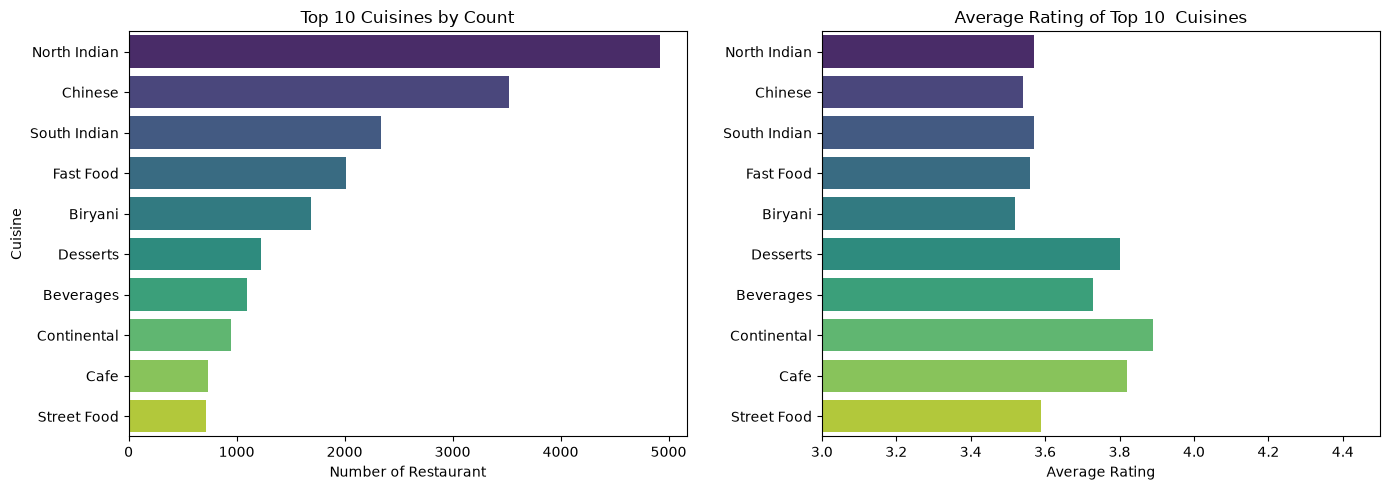

In [81]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.barplot(x=cuisine_summary["restaurants"], y=cuisine_summary.index, hue=cuisine_summary.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Cuisines by Count")
axes[0].set_xlabel("Number of Restaurant")
axes[0].set_ylabel("Cuisine")

sns.barplot(x=cuisine_summary["avg_rating"], y=cuisine_summary.index, hue=cuisine_summary.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Average Rating of Top 10  Cuisines")
axes[1].set_xlabel("Average Rating")
axes[1].set_ylabel(" ")
axes[1].set_xlim(3,4.5)
plt.tight_layout()
plt.show()

**Insight:North Indian is the most common cuisine (about 4900 restaurants) followed by chinese (about 3400), south Indian(about 2200), Fast food
          (about 1900) and Biryani (about 1500).however the most common cuisines average ratings (about 3.6 to 3.7), while smaller categories 
          rate high : Continental (about 3.9), Desserts (about 3.85) and cafe (about 3.85).biryani (about 3.65) and Street food (about 3.6) are 
          the lower end.Note that rating axis start at 3.0 so the gaps look larger in the chart than they are. This shows correlation,not                         causation. 

**Takeway:North Indian and Chinese have the biggest demand but also the most competition. Continental,Dessert and cafe offerings combine higher rating 
          with far fewer restaurants which makes them attractive niches for a new rastaurant.

### Q.Does a higher cost mean a better rating?
**Why: Tests whether charging more is linked to better ratings,which guides pricing decisions.

In [89]:
cost_df=df_rest.dropna(subset=["rate","cost"]).copy()
cost_df["cost_band"]=pd.cut(cost_df["cost"],
                               bins=[0,300,600,1000,2000,10000],
                               labels=["under 300","300-600","600-1000","1000-2000","Above 2000"])
print(cost_df.columns.tolist())
band_summary=cost_df.groupby("cost_band", observed=True).agg(restaurants=("name","count"),
                                                   avg_rating=("rate","mean")).round(2)

print(band_summary)
print("Correlation (cost vs rating):", round (cost_df["cost"].corr(cost_df["rate"]),2))

['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'cost', 'reviews_list', 'menu_item', 'type', 'city', 'cost_band']
            restaurants  avg_rating
cost_band                          
under 300          3104        3.55
300-600            3716        3.57
600-1000           1425        3.72
1000-2000           651        4.10
Above 2000          109        4.14
Correlation (cost vs rating): 0.33


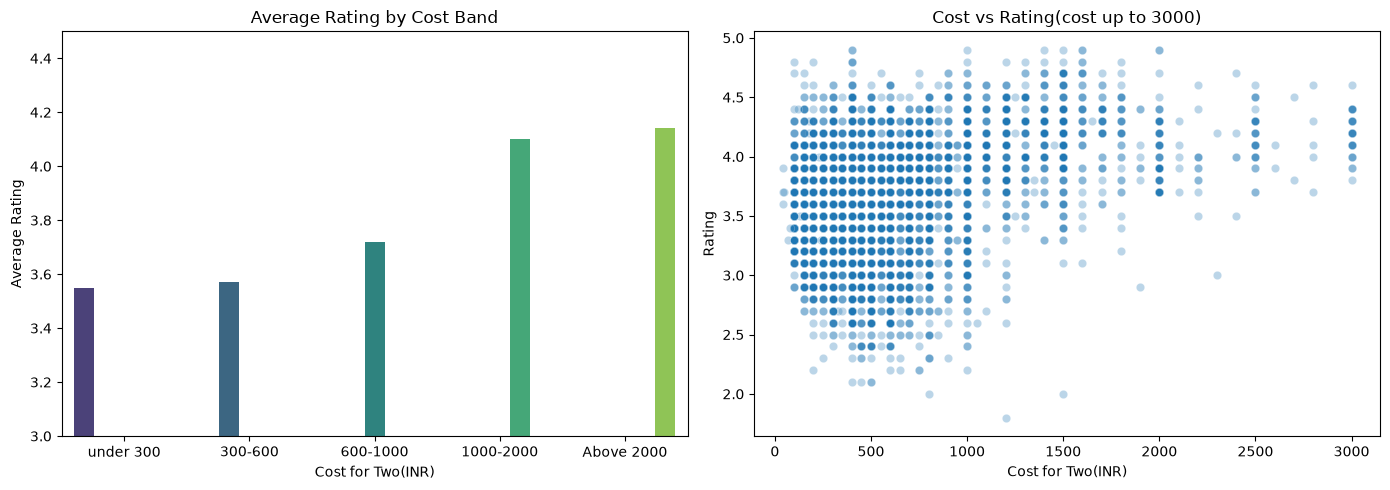

In [90]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.barplot(x=band_summary.index, y=band_summary["avg_rating"], hue=band_summary.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Average Rating by Cost Band")
axes[0].set_xlabel("Cost for Two(INR)")
axes[0].set_ylabel("Average Rating")
axes[0].set_ylim(3,4.5)

sns.scatterplot(data=cost_df[cost_df["cost"] <=3000], x="cost", y="rate", alpha=0.3, ax=axes[1])
axes[1].set_title("Cost vs Rating(cost up to 3000)")
axes[1].set_xlabel("Cost for Two(INR)")
axes[1].set_ylabel("Rating")
plt.tight_layout()
plt.show()

In [ ]:
**Insight: average rating rises steadily with price. Restaurants under ₹300 and in the ₹300-600 band average about 3.55 to 3.6, the ₹600-1000
           band is about3.7, and the ₹1000-2000and above-₹2000 bands reach about 4.1. The scatter plot confirms an upword trends but with a wide spread
           : at every price level there are both low-rated and high-rated restaurants,so price alone dos not gurantee a good rating.The correlation 
           between cost and rating is [r value from your output].Note that rating axis starts at 3.0, so the gaps look larger in the chart than they
           are. this shows correlation, not causation.           

In [ ]:
**Takeway: Premium restaurants are rated higher on average, but customers at higher prices also expect higher quality, so premium pricing only works
           with strong food and service.Budget restaurants do not need a high rating to survive since they dominate the market by volume.

## Q. Which price range has the most restaurants?
**Why: Shows where the market is crowded(budget, mid-range or premium) and where gps may exists.

In [94]:
price_df=df_rest.dropna(subset=["cost"]).copy()
price_df["cost_band"]=pd.cut(price_df["cost"],
                               bins=[0,300,600,1000,2000,10000],
                               labels=["under 300","300-600","600-1000","1000-2000","Above 2000"])
print(cost_df.columns.tolist())
price_summary=price_df["cost_band"].value_counts().sort_index().to_frame("restaurants")
price_summary["share_pct"]=(price_summary["restaurants"]/price_summary["restaurants"].sum()*100).round(1)
print(price_summary)

['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'cost', 'reviews_list', 'menu_item', 'type', 'city', 'cost_band']
            restaurants  share_pct
cost_band                         
under 300          4987       41.2
300-600            4747       39.3
600-1000           1564       12.9
1000-2000           681        5.6
Above 2000          111        0.9


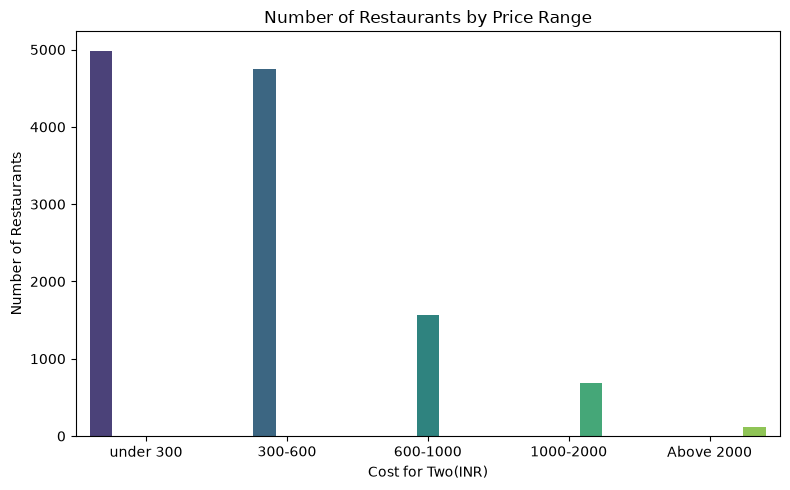

In [95]:
plt.figure(figsize=(8,5))
sns.barplot(x=price_summary.index, y=price_summary["restaurants"], hue=price_summary.index, palette="viridis", legend=False)
plt.title("Number of Restaurants by Price Range")
plt.xlabel("Cost for Two(INR)")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

**Insight: The market is domminated by budget restaurants. The under ₹300 band( about 5000 restaurants) and the ₹300-600 band (about 4800) together
           make up roughly three quarters of all restaurants. the ₹600-1000 band has about 1700 the ₹1000-2000 band about 950 and the above-₹2000
           band only a few hundred. Combined with Q6 where higher price band had higher average ratings (about 4.1 above ₹1000) the premium segment
           is both small and well rated.

**Takeway: Budget and mid low price are the most crowded so competing there needs strong differentiation. Thepremium segment (above ₹1000)has far
           fewer reastaurants and higher ratings but it also needs higher-quality food and service so it is an oppotunityonly for a well-executed
           concept.

## Q.How are votes related to rating?
**Why: Seprates popularrestaurants(many votes) from highly rated ones and shows whether the two go together.

In [97]:
votes_df=df_rest.dropna(subset=["rate"]).copy()
votes_df["votes_band"]=pd.cut(votes_df["votes"],
                               bins=[-1,50,200,1000,10000],
                               labels=["0-50","51-200","201-1000","Above 1000"])
print(cost_df.columns.tolist())
votes_summary=votes_df.groupby("votes_band",observed=True)["rate"].agg(["count","mean"]).round(2)
print(votes_summary)
print("Correlation (votes vs rating):", round (votes_df["votes"].corr(votes_df["rate"]),2))

['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'cost', 'reviews_list', 'menu_item', 'type', 'city', 'cost_band']
            count  mean
votes_band             
0-50         4399  3.43
51-200       2429  3.68
201-1000     1740  3.90
Above 1000    464  4.27
Correlation (votes vs rating): 0.4


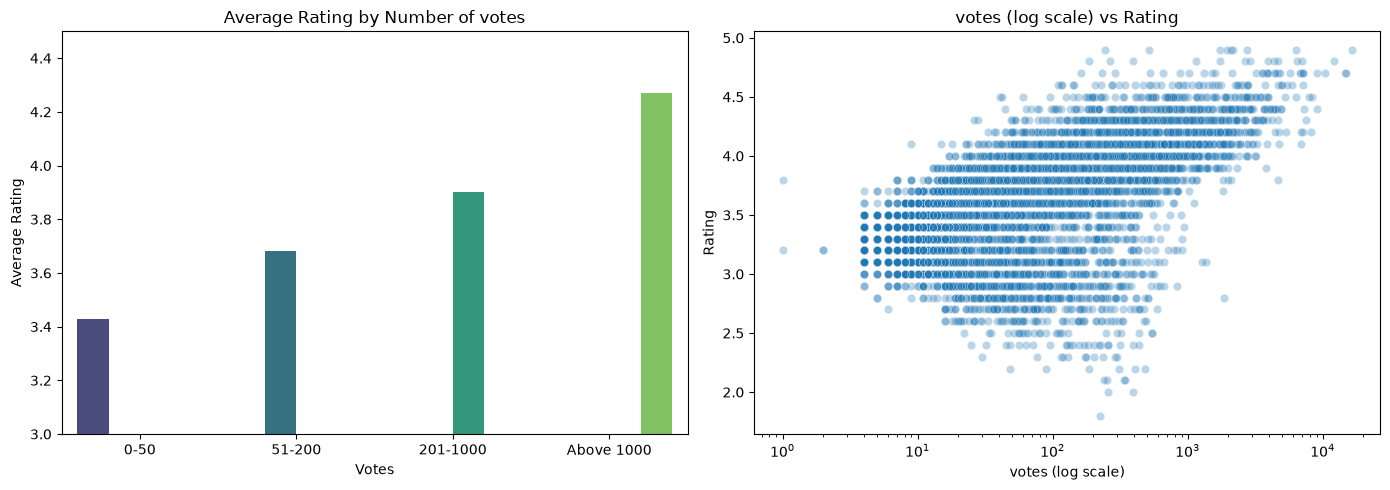

In [98]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.barplot(x=votes_summary.index, y=votes_summary["mean"], hue=votes_summary.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Average Rating by Number of votes")
axes[0].set_xlabel("Votes")
axes[0].set_ylabel("Average Rating")
axes[0].set_ylim(3,4.5)

sns.scatterplot(data=votes_df, x="votes", y="rate", alpha=0.3, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("votes (log scale) vs Rating")
axes[1].set_xlabel("votes (log scale)")
axes[1].set_ylabel("Rating")
plt.tight_layout()
plt.show()

**Insight: Rating rises clearly with the number of votes. Restaurants with 0-50 votes average about 3.4,the 51-200 band about 3.7, the 201-1000
           band about 3.9 and restaurants with over 1000 votes about 4.3.The scatter plot (votes on a log scale)shows the same upward trend,
           although restaurants with similar votes still have a wide range of ratings. the correlationbetween votes and rating is                                  r value from your output. a likely reason is that popular, well liked restaurants attract more customers and reviews, while poorly 
           rated ones get fewer this shows correlatin not causation and restaurants with few vote have less reliable average rating.

**Takeway: Rating and popularity go together so a new restaurant should focus on early customer reviews and consistent quality to build both 
           visibility and rating.

## Q. Which locations have the highest-rated restaurants?
**Why: Locations with high average ratings show where customers expect quality, so a new restaurant needs to match that standard.

In [99]:
loc_df = df_rest.dropna(subset=["rate"]).copy()
loc_summary = loc_df.groupby("location").agg(restaurants=("name", "count"),
                                             avg_rating=("rate", "mean"),
                                             avg_cost=("cost", "mean"))
# Take that restaurants where 30 restaurants are situated
loc_summary = (loc_summary[loc_summary["restaurants"] >= 30].sort_values("avg_rating", ascending=False).round(2))
print(loc_summary.head(10))

                       restaurants  avg_rating  avg_cost
location                                                
Lavelle Road                    52        4.07   1379.81
St. Marks Road                  34        3.93    764.71
Koramangala 5th Block          237        3.91    593.59
Church Street                   53        3.90    783.02
Richmond Road                   66        3.84    915.15
Residency Road                  72        3.83   1007.64
Koramangala 4th Block          103        3.83    648.06
MG Road                         81        3.83   1184.57
Indiranagar                    430        3.79    639.04
Jayanagar                      291        3.76    467.01


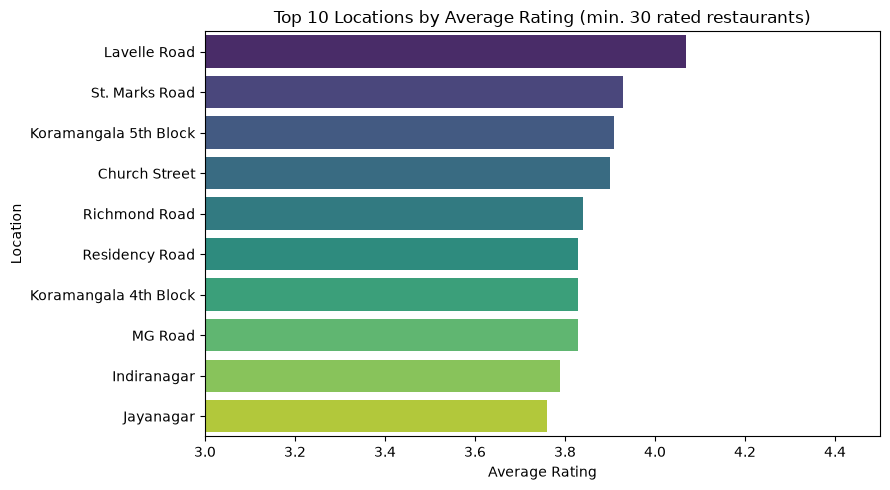

In [100]:
top_loc = loc_summary.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_loc["avg_rating"], y=top_loc.index, hue=top_loc.index, palette="viridis", legend=False)
plt.title("Top 10 Locations by Average Rating (min. 30 rated restaurants)")
plt.xlabel("Average Rating")
plt.ylabel("Location")
plt.xlim(3, 4.5)
plt.tight_layout()
plt.show()

**Insight:Lavelle Road has the highest average rating (about 4.07), followed by St. Marks Road (about 3.93), Koramangala 5th Block (about 3.91) 
          and Church Street (about 3.90). The rest of the top 10 (Richmond Road, Residency Road, Koramangala 4th Block, MG Road, Indiranagar 
          and Jayanagar) sit between about 3.76 and 3.84. Only locations with at least 30 rated restaurants are included, so these averages 
          are reliable. The gap between the 1st and 10th location is about 0.3 rating points, and the rating axis starts at 3.0, so differences 
          look larger in the chart than they are. This shows correlation, not causation.

**Takeway:Customers in these locations expect consistently good quality, so a new restaurant there must match a rating of about 3.8 or
          higher to compete. Lavelle Road stands out as the strongest quality benchmark in the city.

## Q10. Where is the best opportunity to open a new restaurant?
**Why: Combines rating and competition to find locations where customers are satisfied but the market is not overcrowded.

In [101]:
overall_rating = loc_df["rate"].mean()
median_count = loc_summary["restaurants"].median()
opportunity = loc_summary[(loc_summary["avg_rating"] > overall_rating) &
                          (loc_summary["restaurants"] < median_count)].sort_values("avg_rating", ascending=False)

print("Overall avg rating:", round(overall_rating, 2), "| Median rated restaurants per location:", median_count)
print(opportunity.head(10))

Overall avg rating: 3.63 | Median rated restaurants per location: 82.5
                       restaurants  avg_rating  avg_cost
location                                                
Lavelle Road                    52        4.07   1379.81
St. Marks Road                  34        3.93    764.71
Church Street                   53        3.90    783.02
Richmond Road                   66        3.84    915.15
Residency Road                  72        3.83   1007.64
MG Road                         81        3.83   1184.57
Cunningham Road                 47        3.74    727.66
Vasanth Nagar                   42        3.74    845.24
Seshadripuram                   46        3.72    838.04
Koramangala 8th Block           30        3.67    406.90


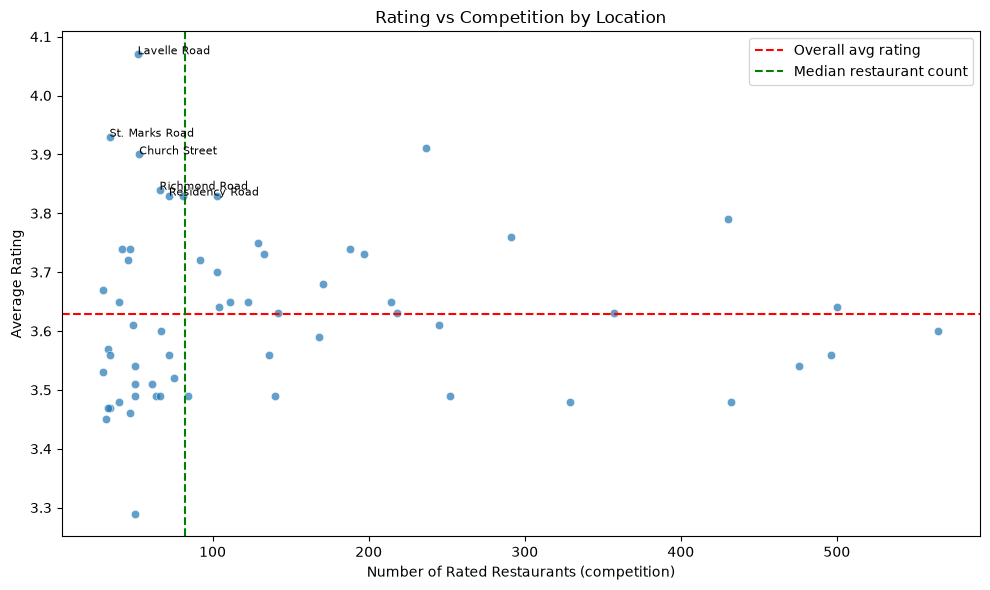

In [102]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=loc_summary, x="restaurants", y="avg_rating", alpha=0.7)
plt.axhline(overall_rating, color="red", linestyle="--", label="Overall avg rating")
plt.axvline(median_count, color="green", linestyle="--", label="Median restaurant count")

for name, row in opportunity.head(5).iterrows():
    plt.annotate(name, (row["restaurants"], row["avg_rating"]), fontsize=8)
plt.title("Rating vs Competition by Location")
plt.xlabel("Number of Rated Restaurants (competition)")
plt.ylabel("Average Rating")
plt.legend()
plt.tight_layout()
plt.show()

**Insight: The overall average rating is about 3.63 and the median location has about 83 rated restaurants. Five locations fall in the
           "opportunity zone" (above-average rating, below-median competition): Lavelle Road (about 4.07 rating, about 53 restaurants), 
            St. Marks Road (about 3.93, about 35), Church Street (about 3.90, about 52), Richmond Road (about 3.84, about 68) and Residency 
            Road (about 3.83, about 74). In contrast, Koramangala 5th Block is also highly rated (about 3.91) but has about 240 rated restaurants,
            so it is much more crowded. Many locations with 100 to 500 restaurants have average or below-average ratings, which shows that heavy 
            competition does not guarantee quality. This shows correlation, not causation.

## Recommendation
For a new restaurant in Bangalore, Lavelle Road, St. Marks Road and Church Street offer the best balance of strong customer ratings and relatively low competition. Based on earlier findings, a sit-down or premium concept (Casual Dining, Cafe or Dessert formats) with table booking and online ordering, priced above Rs. 1,000 for two, matches the segment with the highest ratings and fewer competitors. Quick Bites in the budget range is the most crowded segment and needs strong differentiation.

## Executive Summary
**Business problem: Where, and with what concept, should a new restaurant open in Bangalore?
**Data: About 51,700 Zomato listings, reduced to about 12,000 unique restaurants after cleaning (about 9,000 with ratings).
**Key findings:
- The market is crowded at the bottom: about three quarters of restaurants charge under Rs. 600 for two, and Quick Bites is the most common type.
- Premium restaurants (above Rs. 1,000 for two) are fewer but rated higher (about 4.1), and table booking marks this segment (rating 4.12 vs 3.57).
- Lavelle Road, St. Marks Road and Church Street combine high ratings with relatively low competition.
**Recommendation: Open a premium sit-down concept (Casual Dining, Cafe or Dessert) with table booking and online ordering in one of these low-competition, high-rating locations.

## 6. Key Insights
**Location:The most crowded areas have many restaurants but only average ratings. Lavelle Road (about 4.07), St. Marks Road and Church Street are the              best-rated locations with fewer than the median number of restaurants.
**Online ordering: Restaurants with online ordering rate only slightly higher (3.65 vs 3.59), so it is a minor factor.
**Table booking: Restaurants offering table booking rate much higher (4.12 vs 3.57) and charge about three times more (about Rs. 1,301 vs Rs. 420 for                    two). It marks the premium segment.
**Restaurant type: Quick Bites is the most common type (about 4,900) but rates below Casual Dining, Cafe and Dessert Parlor.
**Cuisine: North Indian and Chinese are the most common cuisines, while Continental, Desserts and Cafe rate higher with fewer restaurants.
**Price: Average rating rises with price, from about 3.55 under Rs. 300 to about 4.1 above Rs. 1,000, while the number of restaurants drops sharply **Votes: Ratings rise with votes (about 3.4 for 0-50 votes to about 4.3 for 1000+), so popularity and ratings go together.

## 7. Recommendations
**Choose the location carefully:Consider Lavelle Road, St. Marks Road or Church Street, where ratings are high and competition is below the median.
**Go for a premium sit-down concept:Casual Dining, Cafe or Dessert formats priced above Rs. 1,000 for two sit in the high-rating, low-competition segment.
**Offer table booking and online ordering from day one:Table booking is common among top-rated restaurants, and online ordering is linked to slightly better ratings.
**Avoid the crowded budget Quick Bites segment:unless there is a clear differentiator, since it has the most competition and average ratings.
**Build early reviews: Ratings and votes rise together, so encourage customer reviews in the first months.

## 8. Limitations
- The data is a snapshot of Zomato listings. It has no sales, revenue, rent or footfall, so profitability cannot be measured.
- Ratings are customer opinions, and about a quarter of restaurants are unrated and excluded from rating analysis.
- Few restaurants in a location does not always mean low competition. It may also mean low demand or high rent.
- All findings show correlation, not causation.
- A restaurant with several cuisines is counted under each cuisine, so cuisine counts add up to more than the number of restaurants.